# SmartBearing CWRU — Perbandingan 9 Algoritma Unsupervised Learning

**Tujuan:** latih dan evaluasi beberapa algoritma *clustering* memakai data fitur getaran CWRU yang sama, lalu pilih metode paling sesuai berdasarkan metrik **training** yang tidak memerlukan label asli.

**Algoritma dibandingkan:** K-Means, MiniBatch K-Means, BIRCH, Gaussian Mixture Model (GMM), Agglomerative, DBSCAN, OPTICS, Spectral Clustering, dan HDBSCAN (jika tersedia).

**Output notebook:**
- `training/outputs/unsupervised_algorithms_comparison.csv` — skor setiap konfigurasi.
- `training/outputs/unsupervised_algorithm_winners.json` — hasil pilihan dan alasan.
- `training/outputs/unsupervised_comparison.png` — grafik komparasi.
- `training/outputs/unsupervised_best_cluster_composition.png`, `unsupervised_best_pca.png` — evaluasi data test.
- `models/best_unsupervised_model.pkl` — **model terbaik yang punya `.predict()` untuk sampel baru** (tidak menimpa `kmeans_pipeline.pkl`).

> **Penting:** semua algoritma yang relevan diuji, bukan secara harfiah setiap algoritma Unsupervised yang ada di dunia. Clustering tidak sama dengan PCA, anomaly detection, atau association rules. Algoritma tanpa `.predict()` native hanya dibandingkan secara eksploratif pada **train**; jangan mengukur kemampuan generalisasi dengan `fit_predict(test)`.

> **Kejujuran evaluasi:** Label `Ball/IR/Normal/OR` tidak digunakan untuk memilih model atau jumlah cluster. Label baru digunakan **setelah pemilihan** untuk memahami hasil pada test. Split dataset per baris/window mungkin memiliki keterkaitan rekaman asal, sehingga hasil test belum membuktikan generalisasi lintas rekaman fisik.

> **PEMBARUAN:** Di bagian **12 — Audit hasil BIRCH** terdapat bukti pemisahan per cluster: tabel komposisi, profil fitur scaled/asli, OR per cluster, jarak ke subcluster, kontribusi fitur, dan grafik. Bagian tersebut dapat dijalankan tanpa mengulangi training 45 konfigurasi.

> **Jika BIRCH sudah terpasang di website:** cukup jalankan bagian 12 untuk audit; Run All akan melatih ulang dan berpotensi menimpa `best_unsupervised_model.pkl` yang sekarang dipakai website. Cadangkan model terlebih dahulu sebelum menjalankan ulang seluruh eksperimen.


## 1 — Import dan cari root repository

Jalankan dari folder proyek atau subfolder `training` / `notebooks`. Kebutuhan: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `joblib`, `ipykernel` (dan Jupyter/VS Code Notebook).

In [1]:
from pathlib import Path
import json, warnings, traceback
from time import perf_counter
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import (
    KMeans, MiniBatchKMeans, Birch, AgglomerativeClustering,
    DBSCAN, OPTICS, SpectralClustering,
)
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score,
)
try:
    from sklearn.cluster import HDBSCAN
    HAS_HDBSCAN = True
except ImportError:
    HAS_HDBSCAN = False

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'preprocessing.py').is_file() and (p / 'models/feature_list.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Root proyek tidak ditemukan. Jalankan notebook dari repository SmartBearing atau subfoldernya.')
OUT = ROOT / 'training' / 'outputs'
OUT.mkdir(parents=True, exist_ok=True)
MODELS_DIR = ROOT / 'models'
SEED = 42
np.random.seed(SEED)
print('Repository:', ROOT)
print('HDBSCAN tersedia:', HAS_HDBSCAN)

Repository: c:\Users\Rendy Breventa\MachineLearning\Minggu2\MachineLearning_Kelompok5\MachineLearning-Kelompok-5
HDBSCAN tersedia: True


## 2 — Baca data hasil preprocessing yang sama

Ketiga belas fitur **sudah di-standardisasi** oleh Data Engineer. Jangan melakukan fitting `StandardScaler` kedua kali. Kolom `label` **dikeluarkan dari data training Unsupervised**.

In [2]:
with (MODELS_DIR / 'feature_list.json').open(encoding='utf-8') as f:
    cfg = json.load(f)
features = cfg['features']
if len(features) != 13 or cfg.get('target') != 'fault_type':
    raise ValueError('Butuh feature_list.json preprocessing 4 kelas dengan 13 fitur.')

train = pd.read_csv(ROOT / 'data/processed/train_scaled.csv')
test = pd.read_csv(ROOT / 'data/processed/test_scaled.csv')
for name, frame in [('train', train), ('test', test)]:
    missing = sorted(set(features + ['label']) - set(frame.columns))
    if missing:
        raise ValueError(f'{name}: kolom tidak ada: {missing}')
    if frame.columns.duplicated().any():
        raise ValueError(f'{name}: ada nama kolom ganda')

X_train = train.loc[:, features].astype(float).to_numpy()
X_test = test.loc[:, features].astype(float).to_numpy()
# Label tersimpan hanya untuk evaluasi eksternal SETELAH memilih algoritma.
y_test = test['label'].astype(int).to_numpy()
if X_train.ndim != 2 or X_train.shape[1] != 13 or X_test.shape[1] != 13:
    raise ValueError('Model mengharapkan 13 fitur numerik.')
if not np.isfinite(X_train).all() or not np.isfinite(X_test).all():
    raise ValueError('Data memiliki NaN atau Infinity.')
if len(X_train) < 40 or len(X_test) < 4:
    raise ValueError('Data kurang untuk perbandingan algoritma.')

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Fitur:', ', '.join(features))
print('Label tidak disertakan pada X_train:', X_train.shape[1] == 13)

Train: (1840, 13) | Test: (460, 13)
Fitur: max, min, mean, sd, rms, skewness, kurtosis, crest, form, peak_to_peak, abs_peak, energy, sd_rms_ratio
Label tidak disertakan pada X_train: True


## 3 — Algoritma dan hyperparameter yang dibandingkan

**Cara pemilihan:** utamakan Silhouette Score pada training, tanpa mengakses label. Aturan kelayakan agar tidak menang karena cluster sepele: minimal 2 cluster, tiap cluster minimal **2%** dari data yang mendapat cluster, dan maksimal **10% noise**. Skor pemilihan = `silhouette × (1 - noise_ratio)`; untuk metode tanpa noise nilainya sama dengan silhouette. Davies–Bouldin sebagai pembanding/tiebreak.

K-Means / MiniBatch / BIRCH / GMM mempunyai `.predict()` native untuk sampel baru (cocok untuk aplikasi web). Agglomerative, Spectral, DBSCAN, OPTICS, dan HDBSCAN standar scikit-learn tidak mempunyai prediksi langsung untuk data baru. Karena itu ada **dua pemenang**: *terbaik eksploratif secara umum* dan *terbaik siap-prediksi untuk website*. Pemenang website disimpan terpisah agar kode lama tidak rusak.

**Catatan:** ini pencarian kandidat terbatas, bukan pembuktian matematis bahwa suatu algoritma selalu unggul. Silhouette dengan jarak Euclidean punya bias terhadap bentuk cluster tertentu. Grafik/profil cluster dan dampak pada tujuan proyek tetap perlu ditinjau.

In [3]:
# Boleh mengubah daftar kandidat jika ingin pencarian lebih luas.
K_OPTIONS = range(2, 7)          # K=2,3,4,5,6
MIN_CLUSTER_SHARE = 0.02        # sekurangnya 2% anggota per cluster
MAX_NOISE_RATIO = 0.10          # paling banyak 10% dianggap noise
SILHOUETTE_SAMPLE = 700         # subsampel acak training untuk evaluasi efisien
RUN_SPECTRAL = True            # boleh False apabila lingkungan tidak mendukung Spectral

candidates = []
for k in K_OPTIONS:
    candidates.extend([
        ('KMeans', {'k':k}, KMeans(n_clusters=k, random_state=SEED, n_init=10, max_iter=300), True),
        ('MiniBatchKMeans', {'k':k}, MiniBatchKMeans(n_clusters=k, random_state=SEED, n_init=10,
                                                   batch_size=256, max_iter=300), True),
        ('BIRCH', {'k':k, 'threshold':0.8}, Birch(n_clusters=k, threshold=0.8), True),
        ('GMM', {'k':k, 'covariance_type':'diag'}, GaussianMixture(n_components=k,
                  covariance_type='diag', reg_covar=1e-5, random_state=SEED, n_init=3, max_iter=200), True),
        ('Agglomerative', {'k':k, 'linkage':'ward'}, AgglomerativeClustering(n_clusters=k,
                                                        linkage='ward'), False),
    ])
    if RUN_SPECTRAL and k <= 4:
        candidates.append(('Spectral', {'k':k, 'affinity':'nearest_neighbors'}, SpectralClustering(
            n_clusters=k, affinity='nearest_neighbors', n_neighbors=12,
            assign_labels='kmeans', random_state=SEED, n_init=10), False))
for eps in [1.0, 1.5, 2.0, 2.5, 3.0]:
    for min_samples in [5, 10]:
        candidates.append(('DBSCAN', {'eps':eps, 'min_samples':min_samples},
                           DBSCAN(eps=eps, min_samples=min_samples), False))
for min_samples in [10, 20]:
    for xi in [0.05, 0.1]:
        candidates.append(('OPTICS', {'min_samples':min_samples, 'xi':xi},
                           OPTICS(min_samples=min_samples, xi=xi, min_cluster_size=0.03), False))
if HAS_HDBSCAN:
    for min_cluster_size in [10, 20, 35]:
        candidates.append(('HDBSCAN', {'min_cluster_size':min_cluster_size},
                           HDBSCAN(min_cluster_size=min_cluster_size, min_samples=5), False))

print('Jumlah konfigurasi yang akan dilatih:', len(candidates))
print('Algoritma:', ', '.join(sorted(set(item[0] for item in candidates))))

Jumlah konfigurasi yang akan dilatih: 45
Algoritma: Agglomerative, BIRCH, DBSCAN, GMM, HDBSCAN, KMeans, MiniBatchKMeans, OPTICS, Spectral


## 4 — Training dan evaluasi seluruh kandidat (tanpa label asli)

**Aturan skor noise:** Untuk DBSCAN/OPTICS/HDBSCAN, label `-1` berarti noise. Silhouette dan Davies–Bouldin dihitung hanya pada anggota yang memperoleh cluster. Rasio noise tetap dicatat dan menjadi penalti serta batas kelayakan. Jangan memperlakukan `-1` sebagai diagnosis atau sebagai satu kelas kerusakan.

Kandidat yang gagal/ tidak membentuk dua cluster dicatat, tidak menghentikan keseluruhan eksperimen. Perbandingan dibuat pada data training, **bukan** pada data testing.

In [4]:
def unsupervised_metrics(X, labels):
    labels = np.asarray(labels)
    assigned = labels != -1
    coverage = float(assigned.mean())
    X_assigned, y_assigned = X[assigned], labels[assigned]
    unique, counts = np.unique(y_assigned, return_counts=True)
    n_clusters = len(unique)
    smallest = float(counts.min() / len(y_assigned)) if len(y_assigned) else 0.0
    out = {
        'n_clusters': int(n_clusters),
        'noise_ratio': float(1.0 - coverage),
        'min_cluster_share': smallest,
        'silhouette': np.nan,
        'davies_bouldin': np.nan,
        'calinski_harabasz': np.nan,
    }
    # Silhouette butuh >=2 cluster dan jumlah cluster < jumlah sampel yang dievaluasi.
    if n_clusters >= 2 and n_clusters < len(y_assigned):
        # Hitung pada 700 sampel (tetap memakai label train); fallback ke full jika cluster terlalu kecil.
        try:
            sample_n = min(SILHOUETTE_SAMPLE, len(y_assigned))
            out['silhouette'] = float(silhouette_score(
                X_assigned, y_assigned, metric='euclidean', sample_size=sample_n, random_state=SEED))
        except ValueError:
            try:
                out['silhouette'] = float(silhouette_score(X_assigned, y_assigned))
            except ValueError:
                pass
        try:
            out['davies_bouldin'] = float(davies_bouldin_score(X_assigned, y_assigned))
            out['calinski_harabasz'] = float(calinski_harabasz_score(X_assigned, y_assigned))
        except ValueError:
            pass
    return out

trained_models = {}
train_predictions = {}
rows = []
for i, (algo, params, estimator, predict_ready) in enumerate(candidates, 1):
    key = f'{algo}__{i:03d}'
    t0 = perf_counter()
    rec = {'id':key, 'algorithm':algo, 'params':json.dumps(params, sort_keys=True),
           'native_predict':bool(predict_ready), 'status':'ok', 'error':''}
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', category=UserWarning)
            if hasattr(estimator, 'fit_predict'):
                labels = estimator.fit_predict(X_train)
            else:
                estimator.fit(X_train)
                labels = estimator.predict(X_train)
        trained_models[key] = estimator
        train_predictions[key] = np.asarray(labels)
        rec.update(unsupervised_metrics(X_train, labels))
        is_valid = (np.isfinite(rec['silhouette']) and rec['n_clusters'] >= 2
                    and rec['noise_ratio'] <= MAX_NOISE_RATIO
                    and rec['min_cluster_share'] >= MIN_CLUSTER_SHARE)
        rec['eligible'] = bool(is_valid)
        rec['selection_score'] = (rec['silhouette'] * (1.0-rec['noise_ratio'])) if is_valid else np.nan
    except Exception as exc:
        rec.update({'status':'failed', 'error':f'{type(exc).__name__}: {exc}',
                    'eligible':False, 'selection_score':np.nan})
    rec['fit_seconds'] = round(perf_counter() - t0, 3)
    rows.append(rec)
    if i % 10 == 0 or i == len(candidates):
        print(f'Selesai {i}/{len(candidates)} konfigurasi...')

results = pd.DataFrame(rows)
results.to_csv(OUT / 'unsupervised_algorithms_comparison.csv', index=False)
print('Berhasil:', int((results.status=='ok').sum()), ' / ',len(results))
print('Memenuhi aturan kelayakan:', int(results.eligible.sum()))
if not results.eligible.any():
    raise RuntimeError('Tidak ada kandidat yang layak. Tinjau aturan kelayakan dan data training.')

ranked = results.loc[results.eligible].sort_values(
    ['selection_score','davies_bouldin'], ascending=[False, True]
).reset_index(drop=True)
columns_to_show = ['algorithm','params','n_clusters','silhouette','davies_bouldin',
                   'noise_ratio','min_cluster_share','selection_score','native_predict']
display(ranked[columns_to_show].head(20).round(4))
print('CSV detail:', OUT / 'unsupervised_algorithms_comparison.csv')

Selesai 10/45 konfigurasi...
Selesai 20/45 konfigurasi...
Selesai 30/45 konfigurasi...
Selesai 40/45 konfigurasi...


c:\ML\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
c:\ML\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
c:\ML\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


Selesai 45/45 konfigurasi...
Berhasil: 45  /  45
Memenuhi aturan kelayakan: 28


,algorithm,params,n_clusters,silhouette,davies_bouldin,noise_ratio,min_cluster_share,selection_score,native_predict
0,Agglomerative,"{""k"": 2, ""linkage"": ""ward""}",2,0.5727,0.7601,0.0000,0.1783,0.5727,False
1,BIRCH,"{""k"": 3, ""threshold"": 0.8}",3,0.5622,0.6764,0.0000,0.0614,0.5622,True
2,BIRCH,"{""k"": 2, ""threshold"": 0.8}",2,0.5620,0.7745,0.0000,0.1598,0.5620,True
3,MiniBatchKMeans,"{""k"": 2}",2,0.5433,0.8275,0.0000,0.2429,0.5433,True
4,MiniBatchKMeans,"{""k"": 3}",3,0.5406,0.9532,0.0000,0.0951,0.5406,True
5,KMeans,"{""k"": 2}",2,0.5356,0.8454,0.0000,0.2647,0.5356,True
6,GMM,"{""covariance_type"": ""diag"", ""k"": 2}",2,0.5125,0.8956,0.0000,0.3120,0.5125,True
7,BIRCH,"{""k"": 4, ""threshold"": 0.8}",4,0.4580,0.8688,0.0000,0.0614,0.4580,True
8,Agglomerative,"{""k"": 6, ""linkage"": ""ward""}",6,0.4408,0.8206,0.0000,0.0804,0.4408,False
9,KMeans,"{""k"": 6}",6,0.4385,0.8635,0.0000,0.0864,0.4385,True


CSV detail: c:\Users\Rendy Breventa\MachineLearning\Minggu2\MachineLearning_Kelompok5\MachineLearning-Kelompok-5\training\outputs\unsupervised_algorithms_comparison.csv


## 5 — Tentukan pemenang secara objektif

**Pemenang analisis:** konfigurasi dengan nilai pemilihan tertinggi di seluruh metode layak.

**Pemenang deployment:** metode terbaik di antara algoritma yang mempunyai `.predict()` native, sehingga mampu memprediksi cluster input website tanpa refit. Keduanya bisa berbeda. Jika berbeda, tidak dibenarkan mengklaim pemenang web paling bagus di seluruh algoritma.

In [5]:
best_any = ranked.iloc[0]
web_candidates = ranked.loc[ranked.native_predict]
if web_candidates.empty:
    raise RuntimeError('Tidak ada model yang dapat memprediksi sampel baru.')
best_web = web_candidates.iloc[0]

for title, item in [('TERBAIK KESELURUHAN (EKSPLORASI)', best_any),
                    ('TERBAIK SIAP UNTUK PREDIKSI WEB', best_web)]:
    print('\n' + title)
    print('Algoritma:', item.algorithm)
    print('Parameter:', item.params)
    print('Silhouette train:',round(float(item.silhouette),4))
    print('Davies–Bouldin train:',round(float(item.davies_bouldin),4))
    print('Noise ratio:',round(float(item.noise_ratio),4))

print('\nJika algoritma berbeda, kandidat web dipilih karena mampu memprediksi input baru.')


TERBAIK KESELURUHAN (EKSPLORASI)
Algoritma: Agglomerative
Parameter: {"k": 2, "linkage": "ward"}
Silhouette train: 0.5727
Davies–Bouldin train: 0.7601
Noise ratio: 0.0

TERBAIK SIAP UNTUK PREDIKSI WEB
Algoritma: BIRCH
Parameter: {"k": 3, "threshold": 0.8}
Silhouette train: 0.5622
Davies–Bouldin train: 0.6764
Noise ratio: 0.0

Jika algoritma berbeda, kandidat web dipilih karena mampu memprediksi input baru.


## 6 — Grafik perbandingan algoritma

Grafik memakai **kandidat terbaik per algoritma** yang memenuhi aturan kelayakan, bukan seluruh konfigurasi. Nilai Silhouette lebih tinggi lebih baik. Perhatikan bahwa skor tertinggi tidak selalu berarti cluster paling selaras dengan label kerusakan.

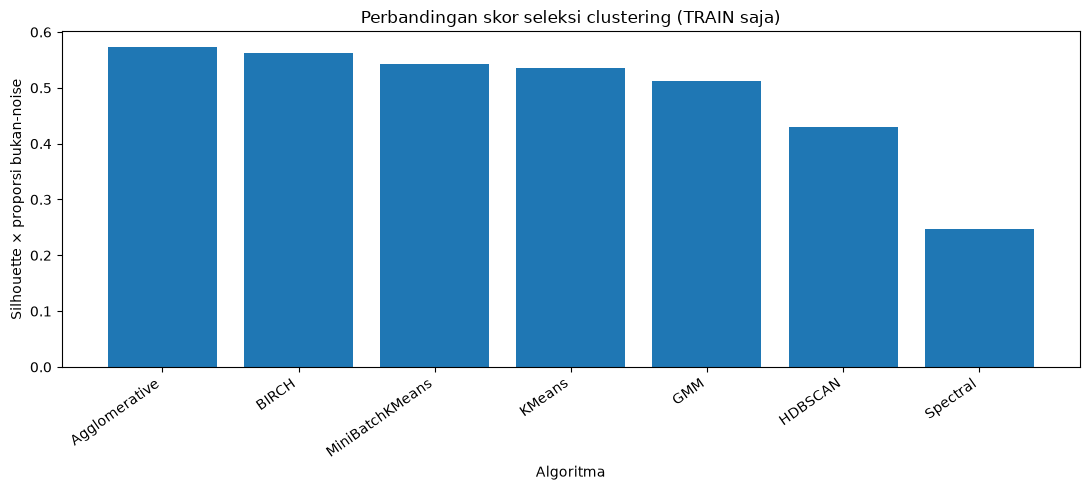

Grafik tersimpan: c:\Users\Rendy Breventa\MachineLearning\Minggu2\MachineLearning_Kelompok5\MachineLearning-Kelompok-5\training\outputs\unsupervised_comparison.png


In [6]:
comparison = (ranked.sort_values('selection_score', ascending=False)
              .drop_duplicates(subset=['algorithm']))
plt.figure(figsize=(11,5))
plt.bar(comparison['algorithm'], comparison['selection_score'])
plt.title('Perbandingan skor seleksi clustering (TRAIN saja)')
plt.ylabel('Silhouette × proporsi bukan-noise')
plt.xlabel('Algoritma')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.savefig(OUT / 'unsupervised_comparison.png', dpi=170)
plt.show()
print('Grafik tersimpan:', OUT / 'unsupervised_comparison.png')

## 7 — Evaluasi pemenang website pada data test yang belum dipakai untuk memilih algoritma

**Baru pada tahap ini** label asli dibuka untuk melihat distribusi Normal/Ball/IR/OR terhadap cluster dan menghitung ARI/NMI. Nilai ARI/NMI tidak dipakai sebagai kriteria untuk memilih pemenang.

Untuk GMM, `.predict()` menghasilkan cluster dengan komponen probabilitas terbesar. Untuk BIRCH, `.predict()` memetakan sampel baru ke cluster berdasarkan subcluster terdekat.

Model terpilih untuk prediksi web: BIRCH
Silhouette test: 0.5457533863037859
Davies–Bouldin test: 0.6481979605562426
ARI test (analisis eksternal): 0.0905
NMI test (analisis eksternal): 0.2762


Cluster,0,1,2,All
Kondisi asli,,,,
Ball,138,0,0,138
IR,138,0,0,138
Normal,46,0,0,46
OR,57,32,49,138
All,379,32,49,460


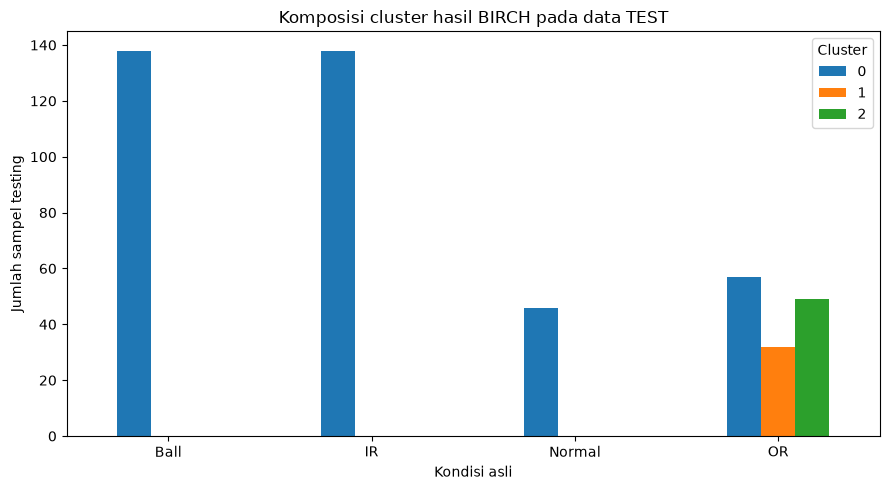

In [7]:
web_model = trained_models[best_web.id]
pred_test = np.asarray(web_model.predict(X_test))
metrics_test = unsupervised_metrics(X_test, pred_test)
encoder = joblib.load(MODELS_DIR / 'label_encoder.pkl')  # hanya muat artefak tepercaya
true_names = encoder.inverse_transform(y_test)
composition = pd.crosstab(pd.Series(true_names,name='Kondisi asli'),
                          pd.Series(pred_test,name='Cluster'), margins=True)

print('Model terpilih untuk prediksi web:',best_web.algorithm)
print('Silhouette test:',metrics_test['silhouette'])
print('Davies–Bouldin test:',metrics_test['davies_bouldin'])
print('ARI test (analisis eksternal):',round(float(adjusted_rand_score(y_test,pred_test)),4))
print('NMI test (analisis eksternal):',round(float(normalized_mutual_info_score(y_test,pred_test)),4))
display(composition)

# Grafik menunjukkan KOMPOSISI, bukan akurasi supervised.
no_total = pd.crosstab(pd.Series(true_names,name='Kondisi asli'),
                       pd.Series(pred_test,name='Cluster'))
ax = no_total.plot(kind='bar', figsize=(9,5))
ax.set_ylabel('Jumlah sampel testing')
ax.set_title(f'Komposisi cluster hasil {best_web.algorithm} pada data TEST')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / 'unsupervised_best_cluster_composition.png',dpi=170)
plt.show()

## 8 — Visualisasi PCA untuk presentasi

PCA hanya dipakai **untuk menggambar** data 13 dimensi menjadi 2 dimensi. Model tidak ditraining pada PCA; model dipilih menggunakan fitur original 13 dimensi yang sudah scaled.

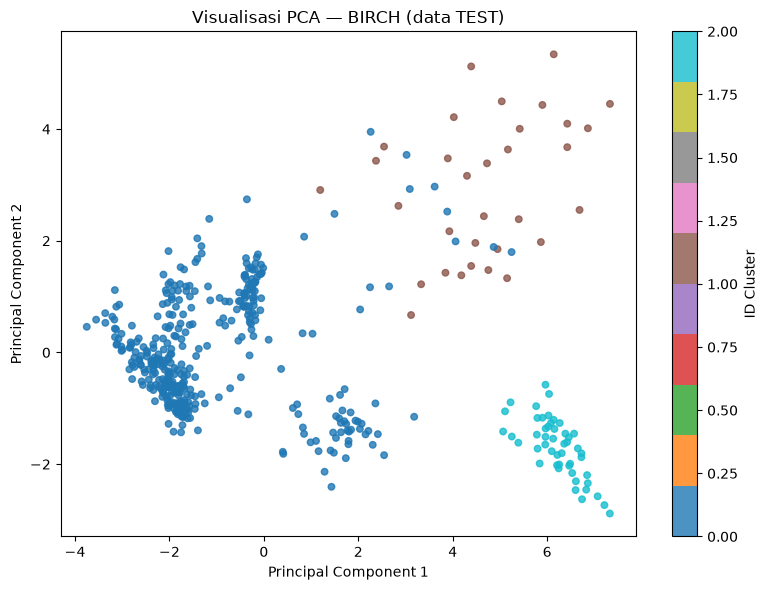

Variansi PCA 2D: 0.8053


In [8]:
pca = PCA(n_components=2, random_state=SEED).fit(X_train)
test_2d = pca.transform(X_test)
plt.figure(figsize=(8,6))
plt.scatter(test_2d[:,0],test_2d[:,1],c=pred_test,cmap='tab10',s=22,alpha=0.8)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title(f'Visualisasi PCA — {best_web.algorithm} (data TEST)')
plt.colorbar(label='ID Cluster')
plt.tight_layout()
plt.savefig(OUT / 'unsupervised_best_pca.png',dpi=170)
plt.show()
print('Variansi PCA 2D:',round(float(pca.explained_variance_ratio_.sum()),4))

## 9 — Ekspor pemenang dengan aman (tanpa merusak model Flask lama)

**PENTING:** Jangan menimpa `models/kmeans_pipeline.pkl` secara otomatis. Backend SmartBearing yang sekarang bisa menganggap model mempunyai metode `.transform()` untuk jarak centroid dan memperlakukan output sebagai K-Means. GMM dan BIRCH memerlukan penyesuaian endpoint/interpretasi.

Notebook ini menyimpan `best_unsupervised_model.pkl` dan metadata terpisah. Saat memutuskan mengganti model website, **backend dan halaman hasil harus disesuaikan serta diuji ulang**. Jika pemenangnya K-Means/MiniBatch, kompatibilitas `.transform()` lebih mudah, tetapi tetap harus diuji.

In [9]:
new_path = MODELS_DIR / 'best_unsupervised_model.pkl'
joblib.dump(web_model,new_path)
reloaded = joblib.load(new_path)     # hanya model yang baru saja dibuat
assert np.array_equal(reloaded.predict(X_test), pred_test)

metadata = {
    'selection_basis': 'training features only; highest silhouette * (1-noise_ratio) subject to eligibility',
    'limits': {'min_cluster_share':MIN_CLUSTER_SHARE,'max_noise_ratio':MAX_NOISE_RATIO},
    'overall_best_exploratory': {'algorithm':best_any.algorithm,'params':json.loads(best_any.params),
                                 'train_score':float(best_any.selection_score)},
    'web_best_predictable': {'algorithm':best_web.algorithm,'params':json.loads(best_web.params),
                             'train_score':float(best_web.selection_score),
                             'model_file':'models/best_unsupervised_model.pkl'},
    'model_input': {'features':features,'scaled':True,'n_features':len(features)},
    'test_metrics_after_selection': {
        'silhouette':None if not np.isfinite(metrics_test['silhouette']) else float(metrics_test['silhouette']),
        'davies_bouldin':None if not np.isfinite(metrics_test['davies_bouldin']) else float(metrics_test['davies_bouldin']),
        'adjusted_rand_index':float(adjusted_rand_score(y_test,pred_test)),
        'normalized_mutual_information':float(normalized_mutual_info_score(y_test,pred_test)),
        'cluster_counts':{str(k):int(v) for k,v in zip(*np.unique(pred_test,return_counts=True))},
    },
    'warning': 'Random row/window split does not prove transfer to independent recordings.',
    'deployment_warning': 'Do not overwrite kmeans_pipeline.pkl without adapting backend for the chosen algorithm.'
}
meta_path = OUT / 'unsupervised_algorithm_winners.json'
meta_path.write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
print('Model baru:',new_path)
print('Metadata:',meta_path)
print('Model lama kmeans_pipeline.pkl TIDAK diubah.')

Model baru: c:\Users\Rendy Breventa\MachineLearning\Minggu2\MachineLearning_Kelompok5\MachineLearning-Kelompok-5\models\best_unsupervised_model.pkl
Metadata: c:\Users\Rendy Breventa\MachineLearning\Minggu2\MachineLearning_Kelompok5\MachineLearning-Kelompok-5\training\outputs\unsupervised_algorithm_winners.json
Model lama kmeans_pipeline.pkl TIDAK diubah.


## 10 — Uji kesesuaian 9 fitur input website ke 13 fitur model baru

Menggunakan `preprocessing.transform_input` yang sudah ada pada proyek, persis seperti website. Ini menguji kompatibilitas input numerik dan scaler (bukan integrasi otomatis ke halaman frontend).

In [10]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0,str(ROOT))
from preprocessing import BASE_FEATURES, transform_input

clean_path = ROOT / 'data/processed/cwru_clean.csv'
if clean_path.exists():
    clean = pd.read_csv(clean_path)
    input_9 = {name: float(clean.iloc[0][name]) for name in BASE_FEATURES}
    scaled_13 = transform_input(input_9, model_dir=MODELS_DIR)
    assert scaled_13.shape == (1,len(features))
    print('Jumlah input form:',len(input_9))
    print('Input ke model setelah preprocessing:',scaled_13.shape)
    print('Cluster dari model baru:',int(reloaded.predict(scaled_13)[0]))
else:
    print('cwru_clean.csv belum ada; tes input web dilewati.')

Jumlah input form: 9
Input ke model setelah preprocessing: (1, 13)
Cluster dari model baru: 0


## 11 — Kesimpulan untuk presentasi dan panduan integrasi

Setelah `Run All`, gunakan angka *nyata* yang muncul dari `unsupervised_algorithm_winners.json` dan tabel perbandingan; **jangan mengarang skor**.

> "Kami membandingkan sembilan keluarga metode clustering pada 13 fitur getaran bearing yang telah distandardisasi. Model dipilih berdasarkan Silhouette Score data training, dengan batas noise dan ukuran cluster agar tidak memilih hasil yang sepele. Kami membedakan model terbaik untuk eksplorasi dan model terbaik yang mampu memprediksi input baru pada website. Label kerusakan hanya digunakan untuk interpretasi dan evaluasi setelah pemilihan model, bukan untuk melatih atau memilih cluster."

**Langkah implementasi:**
1. Simpan notebook ini ke `training/train_unsupervised_compare.ipynb`, lalu jalankan **Run All** dari lingkungan repo SmartBearing dengan CSV hasil preprocessing yang tersedia.
2. Tinjau `training/outputs/unsupervised_algorithms_comparison.csv` dan `unsupervised_algorithm_winners.json`.
3. Jangan mengganti `models/kmeans_pipeline.pkl` dulu. Jika model terbaik untuk web bukan K-Means, minta penyesuaian backend dan frontend agar label/analisis/jarak cluster sesuai jenis algoritma.
4. Uji lagi `python -m pytest -q` dan tes manual pada 4 sampel CWRU setelah integrasi.

**Batasan:** Skor ranking adalah heuristik yang cocok sebagai baseline, bukan jaminan performa industri. Split window acak dan asumsi jarak Euclidean tetap menjadi keterbatasan penelitian.

---
# 12 — AUDIT HASIL CLUSTER BIRCH: BUKTI ANGKA, JARAK, DAN VISUALISASI

**Tujuan lampiran:** tidak hanya melihat bahwa hasilnya `Cluster 0 / 1 / 2`, melainkan menunjukkan bukti terukur **bagaimana sampel ditempatkan ke cluster tersebut** dan **fitur apa yang paling membedakan antarkelompok**.

**Penting (koreksi berdasarkan hasil testing yang sudah dilaporkan):** Pada pengujian sebelumnya, `Cluster 0` berisi `Ball=138, IR=138, Normal=46, OR=57`, sedangkan `Cluster 1` berisi `OR=32` dan `Cluster 2` berisi `OR=49`. Jadi **IR tidak masuk Cluster 1 maupun 2** pada pengujian tersebut. | Label asli | Cluster 0 | Cluster 1 | Cluster 2 |
|---|---:|---:|---:|
| Ball | 138 | 0 | 0 |
| IR | 138 | 0 | 0 |
| Normal | 46 | 0 | 0 |
| OR | 57 | 32 | 49 |

Semua angka dan grafik di bawah **dihitung ulang** dari file `test_scaled.csv` dan `best_unsupervised_model.pkl`; apabila model atau dataset berubah, hasilnya dapat berbeda.

**Lolos secara ilmiah:** kita dapat membuktikan **penugasan berdasarkan jarak ke subcluster dan deskripsi profil fitur**. Namun, perhitungan ini **bukan bukti hubungan sebab-akibat** bahwa satu fitur tertentu secara fisik *menyebabkan* kerusakan OR. Label kelas hanya dipakai sebagai **evaluasi setelah pemilihan model**, bukan bagian dari fitting BIRCH.

### Cara menjalankan tanpa mengulangi 45 training
Lampiran ini **mandiri**: asalkan semua artefak sudah tersimpan, jalankan **seluruh cell mulai dari bagian 12** secara berurutan. Tidak perlu melakukan Run All dari awal hanya untuk mendapatkan tabel/visualisasi bukti pemisahan cluster. Kebutuhan: `data/processed/test_scaled.csv`, `models/best_unsupervised_model.pkl`, `models/scaler.pkl`, `models/label_encoder.pkl`, dan `models/feature_list.json`.

In [11]:
# 12.1 — Memuat model BIRCH terlatih dan data TEST (TANPA fit/latih ulang).
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.cluster import Birch
from sklearn.metrics import pairwise_distances
from IPython.display import display, Markdown

E_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p/'models/feature_list.json').is_file()
               and (p/'data/processed/test_scaled.csv').is_file()), None)
if E_ROOT is None:
    raise FileNotFoundError('Jalankan dari root proyek atau subfolder training/notebooks; file models/ dan data/processed/ wajib tersedia.')
E_OUT = E_ROOT / 'training' / 'outputs'
E_OUT.mkdir(parents=True, exist_ok=True)
with (E_ROOT/'models/feature_list.json').open(encoding='utf-8') as f:
    E_CFG = json.load(f)
E_FEATURES = list(E_CFG['features'])
assert len(E_FEATURES) == 13, 'Model SmartBearing menggunakan 13 fitur.'
E_TEST = pd.read_csv(E_ROOT/'data/processed/test_scaled.csv')
missing = sorted(set(E_FEATURES+['label']) - set(E_TEST.columns))
if missing:
    raise ValueError(f'Kolom data testing belum lengkap: {missing}')
E_X = E_TEST.loc[:, E_FEATURES].to_numpy(dtype=float)
assert np.isfinite(E_X).all(), 'Data testing mengandung nilai bukan angka finite.'
E_MODEL = joblib.load(E_ROOT/'models/best_unsupervised_model.pkl')  # gunakan file sendiri / sumber tepercaya
if not isinstance(E_MODEL, Birch):
    raise TypeError('Lampiran ini menjelaskan mekanisme khusus BIRCH. File best_unsupervised_model.pkl bukan BIRCH.')
assert E_MODEL.n_features_in_ == E_X.shape[1]
E_PRED = np.asarray(E_MODEL.predict(E_X), dtype=int)
E_ENCODER = joblib.load(E_ROOT/'models/label_encoder.pkl')
E_TRUE = E_ENCODER.inverse_transform(E_TEST['label'].astype(int).to_numpy())
E_SCALER = joblib.load(E_ROOT/'models/scaler.pkl')
E_RAW = pd.DataFrame(E_SCALER.inverse_transform(E_X), columns=E_FEATURES)
print('Algoritma:', type(E_MODEL).__name__)
print('Ukuran data TEST:', E_X.shape)
print('Parameter BIRCH:', {'threshold': E_MODEL.threshold,
                           'branching_factor': E_MODEL.branching_factor,
                           'n_clusters': E_MODEL.n_clusters})
print('Cluster terprediksi:', np.unique(E_PRED).tolist())
print('Label asli dipakai hanya untuk evaluasi (tidak untuk fitting).')

Algoritma: Birch
Ukuran data TEST: (460, 13)
Parameter BIRCH: {'threshold': 0.8, 'branching_factor': 50, 'n_clusters': 3}
Cluster terprediksi: [0, 1, 2]
Label asli dipakai hanya untuk evaluasi (tidak untuk fitting).


## 12.2 — Bukti **siapa masuk cluster mana** (label asli vs hasil BIRCH)

Tabel silang di bawah memperlihatkan **jumlah data asli per cluster**. Tabel persentase per-cluster menjelaskan *komposisi* cluster, sedangkan tabel persentase per-kelas menjelaskan berapa banyak sampel suatu kelas masuk cluster tertentu. Kedua jenis persentase **jangan disamakan**.

Contoh jika hasilnya sama seperti sebelumnya: `32/32 = 100%` anggota Cluster 1 berlabel OR, tetapi **bukan** berarti algoritma pasti benar mendiagnosis OR pada semua data baru.

A. JUMLAH sampel per kelas dan cluster:


Cluster,0,1,2
Kondisi asli,,,
Ball,138,0,0
IR,138,0,0
Normal,46,0,0
OR,57,32,49


B. Komposisi tiap CLUSTER (% kolom):


Cluster,0,1,2
Kondisi asli,,,
Ball,36.41,0.0,0.0
IR,36.41,0.0,0.0
Normal,12.14,0.0,0.0
OR,15.04,100.0,100.0


C. Distribusi tiap KELAS ke cluster (% baris):


Cluster,0,1,2
Kondisi asli,,,
Ball,100.0,0.00,0.00
IR,100.0,0.00,0.00
Normal,100.0,0.00,0.00
OR,41.3,23.19,35.51


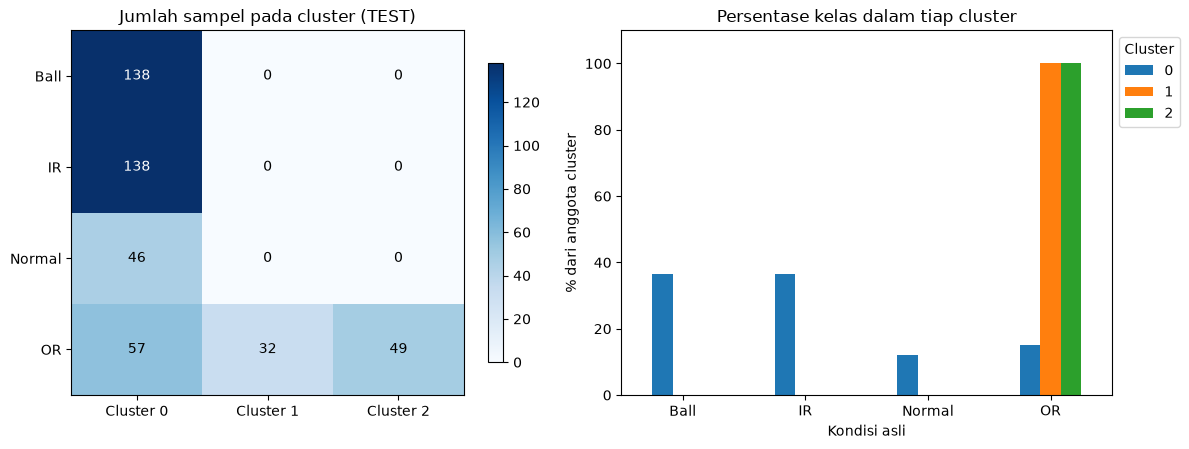

In [12]:
# 12.2 — Crosstab dan grafik bukti komposisi cluster.
E_CROSS = pd.crosstab(
    pd.Series(E_TRUE, name='Kondisi asli'),
    pd.Series(E_PRED, name='Cluster'),
)
E_CROSS.index.name = 'Kondisi asli'
E_CROSS.columns.name = 'Cluster'
E_CROSS_PCT_CLUSTER = (E_CROSS.div(E_CROSS.sum(axis=0), axis=1)*100).round(2)
E_CROSS_PCT_CLASS = (E_CROSS.div(E_CROSS.sum(axis=1), axis=0)*100).round(2)
print('A. JUMLAH sampel per kelas dan cluster:')
display(E_CROSS)
print('B. Komposisi tiap CLUSTER (% kolom):')
display(E_CROSS_PCT_CLUSTER)
print('C. Distribusi tiap KELAS ke cluster (% baris):')
display(E_CROSS_PCT_CLASS)
E_CROSS.to_csv(E_OUT/'birch_bukti_komposisi_cluster.csv')
E_CROSS_PCT_CLUSTER.to_csv(E_OUT/'birch_persentase_per_cluster.csv')
E_CROSS_PCT_CLASS.to_csv(E_OUT/'birch_persentase_per_kelas.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
a = axes[0].imshow(E_CROSS.to_numpy(), aspect='auto', cmap='Blues')
axes[0].set_xticks(range(E_CROSS.shape[1]), [f'Cluster {x}' for x in E_CROSS.columns])
axes[0].set_yticks(range(E_CROSS.shape[0]), E_CROSS.index)
axes[0].set_title('Jumlah sampel pada cluster (TEST)')
for r in range(E_CROSS.shape[0]):
    for c in range(E_CROSS.shape[1]):
        axes[0].text(c, r, str(E_CROSS.iloc[r, c]), ha='center', va='center',
                     color='white' if E_CROSS.iloc[r,c] > 0.55*max(E_CROSS.to_numpy().flat) else 'black')
fig.colorbar(a, ax=axes[0], shrink=.82)
E_CROSS_PCT_CLUSTER.plot(kind='bar', ax=axes[1])
axes[1].set_title('Persentase kelas dalam tiap cluster')
axes[1].set_xlabel('Kondisi asli')
axes[1].set_ylabel('% dari anggota cluster')
axes[1].set_ylim(0, 110)
axes[1].tick_params(axis='x', labelrotation=0)
axes[1].legend(title='Cluster', loc='upper left', bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(E_OUT/'birch_bukti_komposisi_cluster.png', dpi=180, bbox_inches='tight')
plt.show()

## 12.3 — Bukti **fitur apa yang membedakan Cluster 0, 1, dan 2**

Jika dua sampel berbeda label mempunyai kombinasi fitur yang mirip, BIRCH boleh menempatkan keduanya ke cluster sama. Sebaliknya, data dari kelas OR dapat terpisah menjadi beberapa cluster apabila pola numeriknya berbeda.

Tabel profil menyediakan:
- **Median dan rata-rata 13 fitur yang sudah distandardisasi** per cluster. Skala yang sama memudahkan membandingkan fitur.
- **Median fitur dalam satuan sumber** (hasil `inverse_transform` dari scaler yang *sama*), agar perbedaan RMS, kurtosis, crest, dan sebagainya dapat dijelaskan saat presentasi.
- **Ranking beda median absolut terhadap Cluster 0**, sebagai petunjuk fitur yang paling membedakan kelompok. Ini adalah **analisis deskriptif**, bukan feature importance kausal, dan beberapa fitur turunan berkorelasi dengan fitur asal.

In [13]:
# 12.3 — Profil statistik cluster; data mentah direkonstruksi dengan scaler asli.
E_SCALED = pd.DataFrame(E_X, columns=E_FEATURES)
E_SCALED['cluster'] = E_PRED
E_RAW_PROFILE = E_RAW.copy()
E_RAW_PROFILE['cluster'] = E_PRED
E_MEAN_Z = E_SCALED.groupby('cluster')[E_FEATURES].mean()
E_MED_Z = E_SCALED.groupby('cluster')[E_FEATURES].median()
E_MED_RAW = E_RAW_PROFILE.groupby('cluster')[E_FEATURES].median()
E_Q25_RAW = E_RAW_PROFILE.groupby('cluster')[E_FEATURES].quantile(0.25)
E_Q75_RAW = E_RAW_PROFILE.groupby('cluster')[E_FEATURES].quantile(0.75)
print('A. RATA-RATA 13 fitur terstandardisasi (z-score) per cluster:')
display(E_MEAN_Z.round(3))
print('B. MEDIAN 13 fitur terstandardisasi (lebih tahan outlier):')
display(E_MED_Z.round(3))
print('C. MEDIAN 13 fitur dalam satuan fitur SUMBER (sebelum scaling):')
display(E_MED_RAW.round(5))
E_MEAN_Z.to_csv(E_OUT/'birch_profil_mean_scaled.csv')
E_MED_Z.to_csv(E_OUT/'birch_profil_median_scaled.csv')
E_MED_RAW.to_csv(E_OUT/'birch_profil_median_asli.csv')

if 0 in E_MED_Z.index:
    E_BASE_CLUSTER = 0
else:
    E_BASE_CLUSTER = int(E_SCALED['cluster'].value_counts().idxmax())
E_DIFFERENCE = E_MED_Z.subtract(E_MED_Z.loc[E_BASE_CLUSTER], axis=1).abs()
E_DIFF_RANK = E_DIFFERENCE.T.sort_values(by=list(E_DIFFERENCE.index), ascending=False)
print(f'D. Perbedaan absolut MEDIAN scaled terhadap Cluster {E_BASE_CLUSTER}:')
display(E_DIFFERENCE.round(3))
for g in E_MED_Z.index:
    if g == E_BASE_CLUSTER:
        continue
    top = E_DIFFERENCE.loc[g].sort_values(ascending=False).head(5)
    print(f'Cluster {g} paling berbeda dari Cluster {E_BASE_CLUSTER} pada:',
          ', '.join(f'{f} (Δmedian scaled={d:.2f})' for f,d in top.items()))

A. RATA-RATA 13 fitur terstandardisasi (z-score) per cluster:


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,peak_to_peak,abs_peak,energy,sd_rms_ratio
cluster,,,,,,,,,,,,,
0,-0.380,0.391,0.078,-0.362,-0.363,0.040,-0.227,-0.183,-0.333,-0.386,-0.386,-0.379,-0.148
1,1.692,-1.828,-0.095,1.024,1.024,-2.107,2.667,2.032,0.606,1.764,1.793,0.676,0.811
2,2.082,-2.076,-0.565,2.384,2.385,0.603,0.254,0.352,2.243,2.083,2.027,2.746,0.849


B. MEDIAN 13 fitur terstandardisasi (lebih tahan outlier):


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,peak_to_peak,abs_peak,energy,sd_rms_ratio
cluster,,,,,,,,,,,,,
0,-0.605,0.607,-0.242,-0.551,-0.553,0.122,-0.488,-0.428,-0.494,-0.615,-0.617,-0.526,0.321
1,1.579,-1.969,-0.070,1.051,1.050,-1.798,2.527,1.969,0.621,1.811,1.895,0.669,0.821
2,2.095,-2.100,-0.597,2.362,2.363,0.611,0.262,0.385,2.154,2.103,2.028,2.690,0.850


C. MEDIAN 13 fitur dalam satuan fitur SUMBER (sebelum scaling):


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,peak_to_peak,abs_peak,energy,sd_rms_ratio
cluster,,,,,,,,,,,,,
0,0.61416,-0.57307,0.01414,0.17253,0.17283,-0.01820,0.48291,3.67628,12.00531,1.16074,0.61416,0.02987,0.99677
1,4.05480,-4.68875,0.01526,0.65937,0.65937,-0.36792,13.81555,6.42395,44.72985,8.84500,4.68875,0.43477,0.99999
2,4.86690,-4.89700,0.01182,1.05810,1.05789,0.07086,3.80064,4.60819,89.68934,9.76940,4.90580,1.11913,1.00018


D. Perbedaan absolut MEDIAN scaled terhadap Cluster 0:


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,peak_to_peak,abs_peak,energy,sd_rms_ratio
cluster,,,,,,,,,,,,,
0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,2.184,2.576,0.172,1.602,1.603,1.920,3.015,2.397,1.116,2.426,2.511,1.195,0.499
2,2.699,2.707,0.355,2.913,2.916,0.489,0.750,0.813,2.649,2.718,2.645,3.216,0.528


Cluster 1 paling berbeda dari Cluster 0 pada: kurtosis (Δmedian scaled=3.02), min (Δmedian scaled=2.58), abs_peak (Δmedian scaled=2.51), peak_to_peak (Δmedian scaled=2.43), crest (Δmedian scaled=2.40)
Cluster 2 paling berbeda dari Cluster 0 pada: energy (Δmedian scaled=3.22), rms (Δmedian scaled=2.92), sd (Δmedian scaled=2.91), peak_to_peak (Δmedian scaled=2.72), min (Δmedian scaled=2.71)


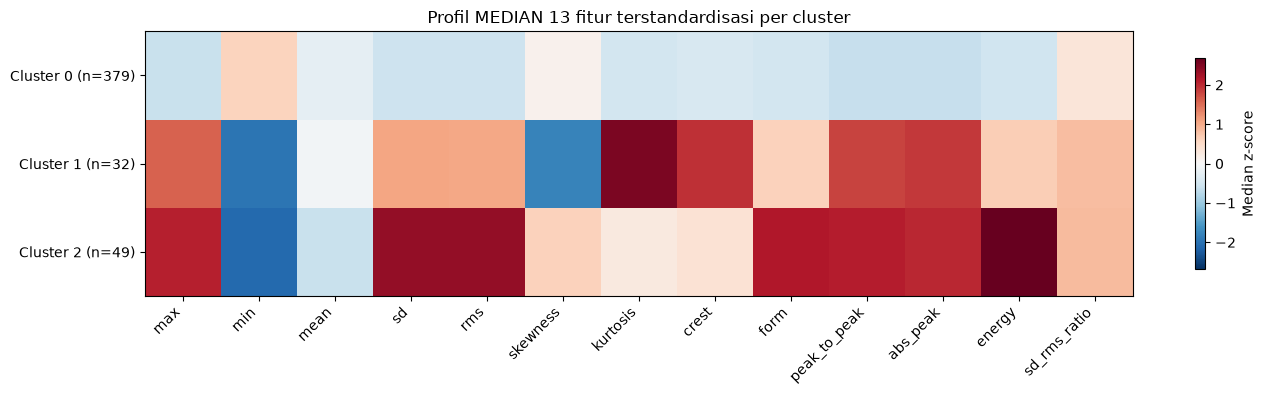

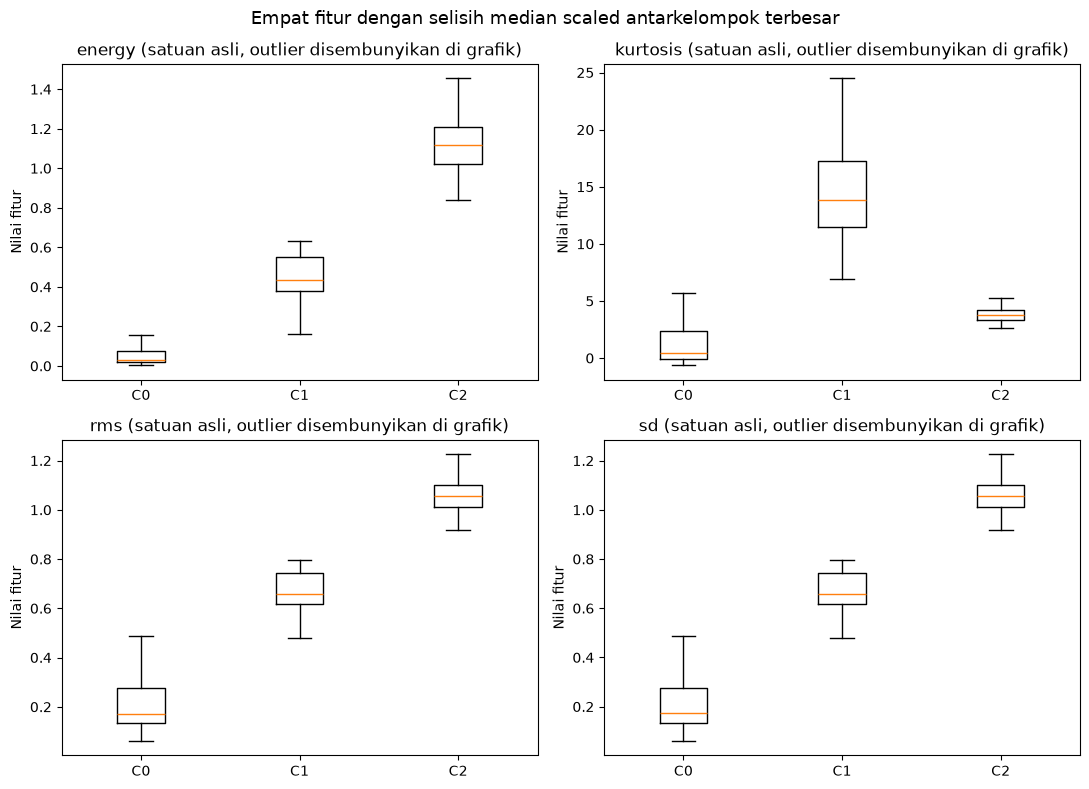

Fitur terpilih berdasarkan selisih median: ['energy', 'kurtosis', 'rms', 'sd']
Catatan: boxplot menonaktifkan gambar titik outlier agar mudah dibaca; data tidak dihapus.


In [14]:
# 12.3b — Grafik heatmap median semua fitur dan boxplot empat fitur pembeda.
fig, ax = plt.subplots(figsize=(14, max(3.5, len(E_MED_Z)*.85+1.5)))
values = E_MED_Z.to_numpy()
maxabs = max(0.5, float(np.nanmax(abs(values))))
im = ax.imshow(values, cmap='RdBu_r', vmin=-maxabs, vmax=maxabs, aspect='auto')
ax.set_xticks(range(len(E_FEATURES)), E_FEATURES, rotation=45, ha='right')
ax.set_yticks(range(len(E_MED_Z)), [f'Cluster {g} (n={sum(E_PRED==g)})' for g in E_MED_Z.index])
ax.set_title('Profil MEDIAN 13 fitur terstandardisasi per cluster')
fig.colorbar(im, ax=ax, label='Median z-score', shrink=.8)
fig.tight_layout()
fig.savefig(E_OUT/'birch_bukti_heatmap_fitur.png', dpi=180, bbox_inches='tight')
plt.show()

E_TOP_FEATURES = E_DIFFERENCE.drop(index=E_BASE_CLUSTER, errors='ignore').max(axis=0).sort_values(ascending=False).head(4).index.tolist()
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.flat, E_TOP_FEATURES):
    groups = [E_RAW_PROFILE.loc[E_RAW_PROFILE.cluster == g, feat].to_numpy() for g in E_MED_Z.index]
    ax.boxplot(groups, positions=range(1, len(groups)+1), showfliers=False)
    ax.set_xticks(range(1,len(groups)+1), [f'C{g}' for g in E_MED_Z.index])
    ax.set_title(feat + ' (satuan asli, outlier disembunyikan di grafik)')
    ax.set_ylabel('Nilai fitur')
fig.suptitle('Empat fitur dengan selisih median scaled antarkelompok terbesar', fontsize=13)
fig.tight_layout()
fig.savefig(E_OUT/'birch_bukti_boxplot_fitur_pembeda.png', dpi=180, bbox_inches='tight')
plt.show()
print('Fitur terpilih berdasarkan selisih median:', E_TOP_FEATURES)
print('Catatan: boxplot menonaktifkan gambar titik outlier agar mudah dibaca; data tidak dihapus.')

## 12.4 — Mengapa khusus data OR bisa terpisah ke beberapa cluster?

Analisis berikut **hanya mengambil sampel berlabel OR setelah model ditetapkan**, lalu menghitung median statistik OR yang masuk ke Cluster 0/1/2. Dengan begitu kita melihat perbedaan di **dalam kelas OR sendiri**, bukan sekadar menyatakan bahwa semua OR identik.

Jika salah satu subkelompok OR punya RMS / kurtosis / crest / form berbeda, ini menjadi **bukti deskriptif** bahwa sampel OR memiliki pola fitur yang berbeda. Penugasan akhir tetap berdasarkan gabungan jarak **semua 13 fitur**, bukan satu kolom saja.

A. Jumlah OR per cluster:


,jumlah_OR
cluster,
0,57
1,32
2,49


B. Median fitur ASLI hanya untuk OR:


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,peak_to_peak,abs_peak,energy,sd_rms_ratio
cluster,,,,,,,,,,,,,
0,0.43914,-0.42182,0.01310,0.13682,0.13739,-0.03202,0.11538,3.31882,12.67699,0.87619,0.46584,0.01888,0.99713
1,4.05480,-4.68875,0.01526,0.65937,0.65937,-0.36792,13.81555,6.42395,44.72985,8.84500,4.68875,0.43477,0.99999
2,4.86690,-4.89700,0.01182,1.05810,1.05789,0.07086,3.80064,4.60819,89.68934,9.76940,4.90580,1.11913,1.00018


C. IQR tiap fitur dalam masing-masing subkelompok OR:


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,peak_to_peak,abs_peak,energy,sd_rms_ratio
cluster,,,,,,,,,,,,,
0,0.17648,0.16961,0.00314,0.03226,0.03247,0.11679,1.13452,1.30937,5.58181,0.26994,0.17085,0.00945,0.00272
1,1.16020,0.93755,0.00265,0.12701,0.12693,0.22504,5.72924,1.35156,12.24554,1.96835,0.96218,0.17272,0.00016
2,0.18860,0.31130,0.00344,0.08843,0.08841,0.02783,0.84176,0.48547,33.89768,0.48400,0.25200,0.18662,0.00005


D. Top 7 fitur yang paling berbeda di ANTARA subkelompok OR (rentang median z-score):


,rentang_median_z
energy,3.216
kurtosis,3.015
rms,2.916
sd,2.913
peak_to_peak,2.718
min,2.707
max,2.699


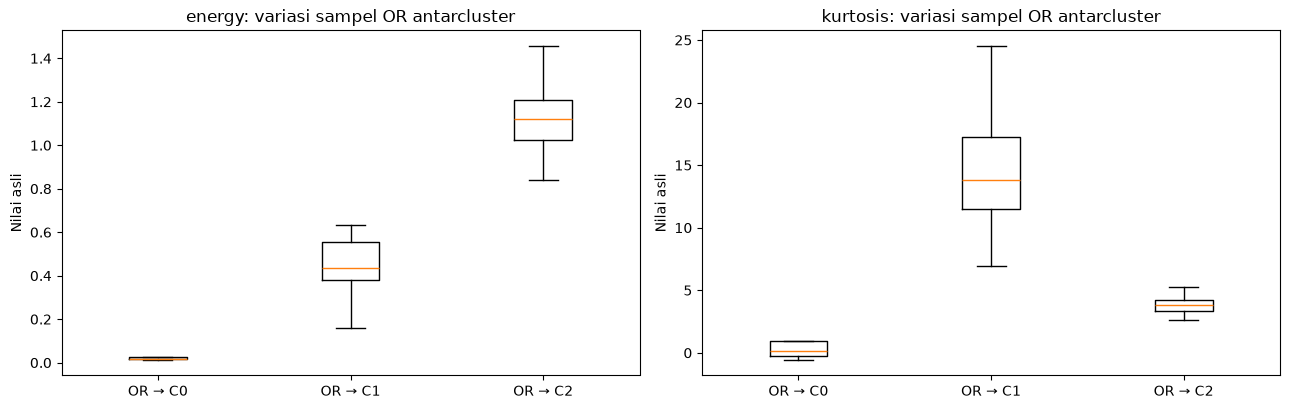

In [15]:
# 12.4 — Profil khusus Outer Race menurut cluster (hasil evaluasi, bukan dasar training).
E_OR_MASK = (np.asarray(E_TRUE) == 'OR')
E_OR_PROFILE = E_RAW_PROFILE.loc[E_OR_MASK].copy()
if E_OR_PROFILE.empty:
    print('Tidak ada sampel OR di data TEST.')
else:
    E_OR_COUNT = E_OR_PROFILE['cluster'].value_counts().sort_index()
    E_OR_MED = E_OR_PROFILE.groupby('cluster')[E_FEATURES].median()
    E_OR_IQR = (E_OR_PROFILE.groupby('cluster')[E_FEATURES].quantile(.75)
                - E_OR_PROFILE.groupby('cluster')[E_FEATURES].quantile(.25))
    print('A. Jumlah OR per cluster:')
    display(E_OR_COUNT.rename('jumlah_OR').to_frame())
    print('B. Median fitur ASLI hanya untuk OR:')
    display(E_OR_MED.round(5))
    print('C. IQR tiap fitur dalam masing-masing subkelompok OR:')
    display(E_OR_IQR.round(5))
    E_OR_MED.to_csv(E_OUT/'birch_profil_OR_per_cluster.csv')
    if E_OR_MED.shape[0] > 1:
        E_OR_MED_Z = E_MED_Z.loc[E_OR_MED.index]
        E_OR_RANGE = (E_OR_MED_Z.max(axis=0) - E_OR_MED_Z.min(axis=0)).sort_values(ascending=False)
        print('D. Top 7 fitur yang paling berbeda di ANTARA subkelompok OR (rentang median z-score):')
        display(E_OR_RANGE.head(7).round(3).rename('rentang_median_z').to_frame())
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
        for ax, feat in zip(axes, E_OR_RANGE.head(2).index):
            grps = [E_OR_PROFILE.loc[E_OR_PROFILE.cluster == g, feat].to_numpy() for g in E_OR_MED.index]
            ax.boxplot(grps, positions=range(1,len(grps)+1), showfliers=False)
            ax.set_xticks(range(1,len(grps)+1), [f'OR → C{g}' for g in E_OR_MED.index])
            ax.set_title(feat + ': variasi sampel OR antarcluster')
            ax.set_ylabel('Nilai asli')
        fig.tight_layout()
        fig.savefig(E_OUT/'birch_bukti_pemisahan_OR.png',dpi=180,bbox_inches='tight')
        plt.show()
    else:
        print('Sampel OR hanya ditemukan pada satu cluster; belum ada subgroup OR untuk dibandingkan.')

## 12.5 — Bukti matematis paling langsung: **jarak ke subcluster BIRCH**

BIRCH tidak menggunakan tiga centroid K-Means biasa. Model mempunyai beberapa **pusat subcluster**, dan masing-masing subcluster memperoleh label cluster akhir.

Untuk satu sampel input \(x\), BIRCH memilih pusat subcluster terdekat menurut jarak Euclidean pada **13 fitur scaled**:

\[
 j^*=\arg\min_j \sqrt{\sum_{f=1}^{13}(x_f-c_{j,f})^2}, \qquad
 \text{Cluster}(x)=\text{subcluster\_labels\_}[j^*].
\]

Kode memverifikasi bahwa pemetaan subcluster terdekat **persis cocok dengan `model.predict()`** pada seluruh baris testing. Untuk tiap sampel ditampilkan jarak minimum ke subcluster dari **setiap cluster akhir**, jarak kelompok alternatif terdekat, dan **margin jarak**. Margin yang kecil berarti posisi sampel relatif dekat dengan batas keputusan; nilai tersebut **bukan probabilitas, keyakinan terkalibrasi, ataupun tingkat kerusakan**.

In [16]:
# 12.5 — Audit BIRCH: nearest subcluster -> label cluster. Tanpa model fitting.
E_CENTERS = np.asarray(E_MODEL.subcluster_centers_, dtype=float)
E_SUB_LABELS = np.asarray(E_MODEL.subcluster_labels_, dtype=int)
if E_CENTERS.ndim != 2 or E_CENTERS.shape[1] != E_X.shape[1]:
    raise RuntimeError('Dimensi pusat subcluster tidak sama dengan fitur model.')
if len(E_SUB_LABELS) != len(E_CENTERS):
    raise RuntimeError('Jumlah label subcluster tidak sesuai pusat subcluster.')
E_DISTS = pairwise_distances(E_X, E_CENTERS, metric='euclidean')
E_NEAREST_SUB = E_DISTS.argmin(axis=1)
E_PRED_FROM_SUB = E_SUB_LABELS[E_NEAREST_SUB]
match = np.array_equal(E_PRED, E_PRED_FROM_SUB)
print('Jumlah pusat subcluster BIRCH:', len(E_CENTERS))
print('Pemetaan nearest-subcluster = BIRCH.predict untuk seluruh TEST:', match)
assert match, 'Mismatch prediksi: periksa versi/scaler/model, jangan klaim bukti sebelum konsisten.'

E_CLUSTERS = np.unique(E_SUB_LABELS)
E_DIST_GROUP = pd.DataFrame({
    f'jarak_ke_C{g}': E_DISTS[:, E_SUB_LABELS == g].min(axis=1)
    for g in E_CLUSTERS
})
E_RANK = np.argsort(E_DIST_GROUP.to_numpy(), axis=1)
E_WINNER = E_RANK[:,0]
E_RUNNER = E_RANK[:,1]
E_NEAR_DISTANCE = E_DIST_GROUP.to_numpy()[np.arange(len(E_X)), E_WINNER]
E_ALT_DISTANCE = E_DIST_GROUP.to_numpy()[np.arange(len(E_X)), E_RUNNER]
E_MARGINS = E_ALT_DISTANCE-E_NEAR_DISTANCE
assert np.all(E_MARGINS >= -1e-7)
E_ASSIGN = pd.DataFrame({
    'baris_test': np.arange(len(E_X)),
    'label_asli': E_TRUE,
    'cluster_prediksi': E_PRED,
    'subcluster_terdekat': E_NEAREST_SUB,
    'jarak_ke_subcluster_terdekat': E_NEAR_DISTANCE,
    'cluster_alternatif_terdekat': E_CLUSTERS[E_RUNNER],
    'jarak_ke_cluster_alternatif': E_ALT_DISTANCE,
    'margin_jarak': E_MARGINS,
})
E_ASSIGN = pd.concat([E_ASSIGN, E_DIST_GROUP], axis=1)
print('Bukti 15 baris pertama, dengan jarak ke tiap cluster:')
display(E_ASSIGN.head(15).round(4))
print('Distribusi jarak dan margin menurut cluster:')
display(E_ASSIGN.groupby('cluster_prediksi')[
    ['jarak_ke_subcluster_terdekat', 'jarak_ke_cluster_alternatif', 'margin_jarak']
].agg(['median','mean','min','max']).round(4))
E_ASSIGN.to_csv(E_OUT/'birch_bukti_jarak_setiap_sampel.csv', index=False)
print('CSV lengkap:', E_OUT/'birch_bukti_jarak_setiap_sampel.csv')

Jumlah pusat subcluster BIRCH: 107
Pemetaan nearest-subcluster = BIRCH.predict untuk seluruh TEST: True
Bukti 15 baris pertama, dengan jarak ke tiap cluster:


,baris_test,label_asli,cluster_prediksi,subcluster_terdekat,jarak_ke_subcluster_terdekat,cluster_alternatif_terdekat,jarak_ke_cluster_alternatif,margin_jarak,jarak_ke_C0,jarak_ke_C1,jarak_ke_C2
0,0,OR,1,90,0.5646,0,3.9921,3.4275,3.9921,0.5646,5.2906
1,1,Ball,0,5,0.4194,1,5.9620,5.5426,0.4194,5.9620,7.8338
2,2,IR,0,11,0.5096,1,6.0703,5.5608,0.5096,6.0703,8.0079
3,3,OR,0,5,0.2984,1,5.9684,5.6699,0.2984,5.9684,7.8968
4,4,Ball,0,31,1.6391,1,5.6689,4.0299,1.6391,5.6689,7.4893
5,5,Normal,0,6,0.3864,1,6.0392,5.6528,0.3864,6.0392,8.7035
6,6,Ball,0,5,0.9923,1,5.9544,4.9621,0.9923,5.9544,7.6457
7,7,Ball,0,5,0.4625,1,5.7607,5.2983,0.4625,5.7607,7.7013
8,8,OR,2,66,0.5409,0,3.1978,2.6569,3.1978,3.2298,0.5409
9,9,IR,0,8,0.2724,1,4.0812,3.8088,0.2724,4.0812,6.0855


Distribusi jarak dan margin menurut cluster:


jarak_ke_subcluster_terdekat                          \
                                       median    mean     min     max   
cluster_prediksi                                                        
0                                      0.5963  0.6351  0.1748  1.8815   
1                                      0.9811  0.9846  0.4783  1.9908   
2                                      0.5845  0.6143  0.2274  1.2512   

                 jarak_ke_cluster_alternatif                          \
                                      median    mean     min     max   
cluster_prediksi                                                       
0                                     5.6310  5.1025  1.1928  8.7399   
1                                     1.7341  2.2802  1.1528  4.4663   
2                                     3.2711  3.3080  1.9901  4.9517   

                 margin_jarak                          
                       median    mean     min     max  
cluster_prediksi                                       
0                      4.9845  4.4674  0.0705  7.2430  
1                      0.8511  1.2956  0.0815  3.7292  
2                      2.7351  2.6936  0.9594  4.2434

CSV lengkap: c:\Users\Rendy Breventa\MachineLearning\Minggu2\MachineLearning_Kelompok5\MachineLearning-Kelompok-5\training\outputs\birch_bukti_jarak_setiap_sampel.csv


## 12.6 — Fitur yang memberi kontribusi pada pilihan jarak setiap sampel

Untuk setiap sampel, kita bandingkan pusat subcluster terdekat (*terpilih*) dengan pusat subcluster terdekat dari cluster alternatif. Untuk fitur \(f\):

\[
 \Delta_f=(x_f-c_{\text{alternatif},f})^2-(x_f-c_{\text{terpilih},f})^2.
\]

- \(\Delta_f>0\): fitur tersebut membuat subcluster terpilih **lebih dekat** daripada alternatif.
- \(\Delta_f<0\): fitur tersebut justru lebih mendukung alternatif.
- \(\sum_f \Delta_f\): selisih kuadrat jarak kedua subcluster, sehingga totalnya non-negatif jika pilihan terdekat benar.

Ini merupakan **bukti matematis penugasan cluster pada model terlatih**, tetapi bukan penjelasan sebab-akibat mekanis maupun *feature importance* global yang independen (fitur turunan saling berkorelasi).

Contoh kontribusi per fitur untuk 10 sampel pertama:


,baris_test,label_asli,cluster,max,min,mean,sd,rms,skewness,kurtosis,crest,form,peak_to_peak,abs_peak,energy,sd_rms_ratio,keuntungan_jarak_kuadrat_total
0,0,OR,1,1.661,0.866,0.015,0.056,0.056,-0.044,7.337,3.025,-0.016,1.234,1.348,0.078,0.000,15.618
1,1,Ball,0,1.899,2.205,0.931,0.820,0.822,7.220,9.593,7.296,0.124,2.058,2.108,0.256,0.036,35.369
2,2,IR,0,1.470,1.691,5.429,0.660,0.649,6.710,8.128,3.804,0.412,1.585,1.637,0.223,4.190,36.589
3,3,OR,0,2.022,2.165,0.948,1.015,1.017,7.611,9.163,6.733,0.194,2.103,2.099,0.285,0.179,35.532
4,4,Ball,0,5.224,3.829,-0.094,1.605,1.608,1.866,3.125,1.117,0.641,4.512,4.926,1.071,0.020,29.450
5,5,Normal,0,0.727,1.019,0.033,0.330,0.328,7.775,11.194,9.352,0.396,0.871,0.988,0.026,3.284,36.323
6,6,Ball,0,1.714,2.010,2.183,0.650,0.653,7.561,9.391,6.672,-0.205,1.867,1.919,0.226,-0.170,34.471
7,7,Ball,0,1.809,2.014,0.745,0.713,0.714,6.243,9.265,7.238,0.107,1.919,1.955,0.238,0.012,32.972
8,8,OR,2,0.994,1.669,0.026,0.961,0.963,0.033,0.230,-0.020,0.168,1.317,1.040,2.552,0.000,9.933
9,9,IR,0,0.587,0.840,0.160,0.288,0.288,8.115,3.959,0.545,0.145,0.712,0.736,0.127,0.080,16.582



Cluster 0: lima fitur dengan RATA-RATA Δ jarak kuadrat terbesar (positif mendukung penugasan):


,rerata_delta_jarak_kuadrat
kurtosis,6.823
skewness,5.551
crest,3.816
sd_rms_ratio,1.836
min,1.728



Cluster 1: lima fitur dengan RATA-RATA Δ jarak kuadrat terbesar (positif mendukung penugasan):


,rerata_delta_jarak_kuadrat
skewness,2.574
kurtosis,1.093
crest,0.511
max,0.238
min,0.238



Cluster 2: lima fitur dengan RATA-RATA Δ jarak kuadrat terbesar (positif mendukung penugasan):


,rerata_delta_jarak_kuadrat
energy,2.818
form,1.538
rms,1.017
sd,1.015
skewness,0.920


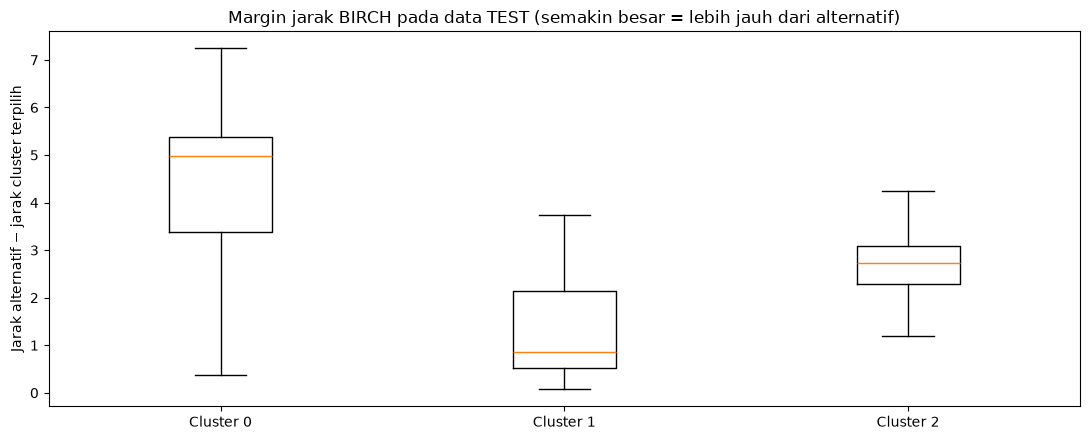

In [17]:
# 12.6 — Decomposisi margin jarak kuadrat per fitur (untuk setiap sampel).
E_CHOSEN_CENTERS = E_CENTERS[E_NEAREST_SUB]
E_ALT_SUB = np.empty(len(E_X), dtype=int)
for i, g in enumerate(E_CLUSTERS[E_RUNNER]):
    choices = np.where(E_SUB_LABELS == g)[0]
    E_ALT_SUB[i] = int(choices[np.argmin(E_DISTS[i, choices])])
E_ALT_CENTERS = E_CENTERS[E_ALT_SUB]
E_CONTRIB = (E_X-E_ALT_CENTERS)**2 - (E_X-E_CHOSEN_CENTERS)**2
E_TOTAL = E_CONTRIB.sum(axis=1)
assert np.allclose(E_TOTAL, E_ALT_DISTANCE**2-E_NEAR_DISTANCE**2, atol=1e-7)
E_CONTRIB_DF = pd.DataFrame(E_CONTRIB, columns=E_FEATURES)
E_CONTRIB_DF.insert(0, 'cluster', E_PRED)
E_CONTRIB_DF.insert(0, 'label_asli', E_TRUE)
E_CONTRIB_DF.insert(0, 'baris_test', np.arange(len(E_X)))
E_CONTRIB_DF['keuntungan_jarak_kuadrat_total'] = E_TOTAL
print('Contoh kontribusi per fitur untuk 10 sampel pertama:')
display(E_CONTRIB_DF.head(10).round(3))
E_CONTRIB_DF.to_csv(E_OUT/'birch_bukti_kontribusi_jarak_fitur.csv', index=False)
E_SUMMARIES = []
for g in sorted(np.unique(E_PRED)):
    group = E_CONTRIB_DF[E_CONTRIB_DF['cluster'] == g]
    mean_impact = group[E_FEATURES].mean().sort_values(ascending=False)
    print(f'\nCluster {g}: lima fitur dengan RATA-RATA Δ jarak kuadrat terbesar (positif mendukung penugasan):')
    display(mean_impact.head(5).round(3).rename('rerata_delta_jarak_kuadrat').to_frame())
    for feat, val in mean_impact.items():
        E_SUMMARIES.append({'cluster': int(g),'fitur':feat,'rerata_delta_jarak_kuadrat':float(val)})
E_DRIVERS = pd.DataFrame(E_SUMMARIES)
E_DRIVERS.to_csv(E_OUT/'birch_bukti_fitur_pembedaan_jarak.csv',index=False)

fig, ax = plt.subplots(figsize=(11,4.5))
positions = list(range(len(E_CLUSTERS)))
ax.boxplot([E_ASSIGN.loc[E_ASSIGN.cluster_prediksi==g,'margin_jarak'].to_numpy()
            for g in E_CLUSTERS], positions=range(1,len(E_CLUSTERS)+1), showfliers=False)
ax.set_xticks(range(1,len(E_CLUSTERS)+1),[f'Cluster {g}' for g in E_CLUSTERS])
ax.set_ylabel('Jarak alternatif − jarak cluster terpilih')
ax.set_title('Margin jarak BIRCH pada data TEST (semakin besar = lebih jauh dari alternatif)')
fig.tight_layout()
fig.savefig(E_OUT/'birch_bukti_margin_jarak.png', dpi=180, bbox_inches='tight')
plt.show()

## 12.7 — Kesimpulan otomatis untuk presentasi (berdasarkan hasil aktual)

Bagian ini menyusun narasi **dari tabel yang benar-benar dihitung**, sehingga tidak perlu menebak angka atau menyebut Cluster 1 dan 2 berisi IR jika ternyata tidak ada. Narasi akan disimpan ke `training/outputs/birch_penjelasan_pemisahan_cluster.md` dan dapat dijadikan lampiran presentasi.

**Batasan utama:** penugasan ke cluster ditentukan oleh *kedekatan ke pusat subcluster pada fitur scaled*, bukan oleh label. Nilai ARI/NMI rendah tetap berarti kemiripan cluster terhadap empat kategori kerusakan rendah walaupun struktur geometris antarcluster terlihat. Pembagian train-test acak per window belum membuktikan generalisasi ke rekaman bearing independen.

In [18]:
# 12.7 — Rangkuman otomatis berdasarkan HASIL AKTUAL data TEST.
lines = [
    '# Bukti Pemisahan Cluster BIRCH — SmartBearing CWRU',
    '',
    f'- Data testing: {len(E_X)} baris, {len(E_FEATURES)} fitur scaled.',
    f'- Model: BIRCH (threshold={E_MODEL.threshold}, branching_factor={E_MODEL.branching_factor}, n_clusters={E_MODEL.n_clusters}).',
    f'- Jumlah subcluster pada CF Tree: {len(E_CENTERS)}.',
    '- Audit jarak: semua hasil prediksi cocok dengan subcluster terdekat = ' + str(bool(match)) + '.',
    '',
    '## Distribusi per cluster (hanya evaluasi setelah training)',
]
for g in sorted(np.unique(E_PRED)):
    in_g = E_CROSS[g].sort_values(ascending=False) if g in E_CROSS.columns else pd.Series(dtype=int)
    counts = ', '.join(f'{k}={v}' for k,v in in_g.items() if v)
    lines.append(f'- Cluster {g}: {sum(E_PRED==g)} sampel ({counts}).')
lines += ['', '## Bukti profil fitur (median z-score vs cluster baseline)']
for g in sorted(np.unique(E_PRED)):
    if g == E_BASE_CLUSTER:
        continue
    top = E_DIFFERENCE.loc[g].sort_values(ascending=False).head(5)
    lines.append(f'- Cluster {g} dibanding Cluster {E_BASE_CLUSTER}: ' + ', '.join(f'{k} (Δmedian z={v:.3f})' for k,v in top.items()) + '.')
lines += ['', '## Bukti penugasan sampel',
    'Setiap sampel dipetakan ke pusat subcluster BIRCH terdekat menurut jarak Euclidean dalam 13 fitur scaled.',
    'Tabel penuh ada di `birch_bukti_jarak_setiap_sampel.csv`, termasuk jarak ke subcluster dari setiap cluster akhir dan margin pilihan.',
    'Kontribusi kuadrat jarak per fitur ada di `birch_bukti_kontribusi_jarak_fitur.csv`.',
    '',
    '## Batasan',
    '- Komposisi kelas adalah label referensi untuk evaluasi, bukan input fitting BIRCH.',
    '- Cluster tidak otomatis berarti diagnosis OR atau tingkat kerusakan.',
    '- Fitur turunan mungkin saling berkorelasi; statistik ini deskriptif dan tidak membuktikan kausalitas.',
    '- Dataset dipisah per window/baris dan belum divalidasi antarrekaman independen.',
]
E_REPORT = '\n'.join(lines) + '\n'
(E_OUT/'birch_penjelasan_pemisahan_cluster.md').write_text(E_REPORT, encoding='utf-8')
display(Markdown(E_REPORT))
print('\nFILE BUKTI BERHASIL DISIMPAN KE:', E_OUT)
print('\nDaftar file bukti:')
for name in ['birch_bukti_komposisi_cluster.csv','birch_bukti_komposisi_cluster.png',
             'birch_profil_mean_scaled.csv','birch_profil_median_scaled.csv',
             'birch_profil_median_asli.csv','birch_bukti_heatmap_fitur.png',
             'birch_bukti_boxplot_fitur_pembeda.png','birch_profil_OR_per_cluster.csv',
             'birch_bukti_pemisahan_OR.png','birch_bukti_jarak_setiap_sampel.csv',
             'birch_bukti_kontribusi_jarak_fitur.csv','birch_bukti_fitur_pembedaan_jarak.csv',
             'birch_bukti_margin_jarak.png','birch_penjelasan_pemisahan_cluster.md']:
    file=E_OUT/name
    print(('✓' if file.exists() else '–'), file.name)

# Bukti Pemisahan Cluster BIRCH — SmartBearing CWRU

- Data testing: 460 baris, 13 fitur scaled.
- Model: BIRCH (threshold=0.8, branching_factor=50, n_clusters=3).
- Jumlah subcluster pada CF Tree: 107.
- Audit jarak: semua hasil prediksi cocok dengan subcluster terdekat = True.

## Distribusi per cluster (hanya evaluasi setelah training)
- Cluster 0: 379 sampel (Ball=138, IR=138, OR=57, Normal=46).
- Cluster 1: 32 sampel (OR=32).
- Cluster 2: 49 sampel (OR=49).

## Bukti profil fitur (median z-score vs cluster baseline)
- Cluster 1 dibanding Cluster 0: kurtosis (Δmedian z=3.015), min (Δmedian z=2.576), abs_peak (Δmedian z=2.511), peak_to_peak (Δmedian z=2.426), crest (Δmedian z=2.397).
- Cluster 2 dibanding Cluster 0: energy (Δmedian z=3.216), rms (Δmedian z=2.916), sd (Δmedian z=2.913), peak_to_peak (Δmedian z=2.718), min (Δmedian z=2.707).

## Bukti penugasan sampel
Setiap sampel dipetakan ke pusat subcluster BIRCH terdekat menurut jarak Euclidean dalam 13 fitur scaled.
Tabel penuh ada di `birch_bukti_jarak_setiap_sampel.csv`, termasuk jarak ke subcluster dari setiap cluster akhir dan margin pilihan.
Kontribusi kuadrat jarak per fitur ada di `birch_bukti_kontribusi_jarak_fitur.csv`.

## Batasan
- Komposisi kelas adalah label referensi untuk evaluasi, bukan input fitting BIRCH.
- Cluster tidak otomatis berarti diagnosis OR atau tingkat kerusakan.
- Fitur turunan mungkin saling berkorelasi; statistik ini deskriptif dan tidak membuktikan kausalitas.
- Dataset dipisah per window/baris dan belum divalidasi antarrekaman independen.



FILE BUKTI BERHASIL DISIMPAN KE: c:\Users\Rendy Breventa\MachineLearning\Minggu2\MachineLearning_Kelompok5\MachineLearning-Kelompok-5\training\outputs

Daftar file bukti:
✓ birch_bukti_komposisi_cluster.csv
✓ birch_bukti_komposisi_cluster.png
✓ birch_profil_mean_scaled.csv
✓ birch_profil_median_scaled.csv
✓ birch_profil_median_asli.csv
✓ birch_bukti_heatmap_fitur.png
✓ birch_bukti_boxplot_fitur_pembeda.png
✓ birch_profil_OR_per_cluster.csv
✓ birch_bukti_pemisahan_OR.png
✓ birch_bukti_jarak_setiap_sampel.csv
✓ birch_bukti_kontribusi_jarak_fitur.csv
✓ birch_bukti_fitur_pembedaan_jarak.csv
✓ birch_bukti_margin_jarak.png
✓ birch_penjelasan_pemisahan_cluster.md
